# Assignment A2

Compare **Two-Stage Object Detection** and **One-Stage Object Detection** approaches on the Pascal VOC dataset.

Evaluate and compare the following architectures:

- **Two-Stage Detector:** Faster R-CNN (VGG16 Backbone)
- **One-Stage Detector:** YOLO11n

Train and evaluate the models using a consistent dataset split and evaluation protocol.

1. **Detection Accuracy:** mAP, mAP@0.5, and mAP@0.75.
2. **Training Efficiency:** Total training time and average time per epoch.
3. **Model Complexity:** Total parameters, trainable parameters, model size, and computational cost (FLOPs).
4. **Detection Analysis:** Loss curves, Precision–Recall curves, confusion matrices, and qualitative detection results.

## Setup PC

In [83]:
def clean():
    import gc
    import torch

    # Release cached GPU memory
    gc.collect()
    torch.cuda.empty_cache()

clean()

In [84]:
!nvidia-smi

Sat Nov 14 22:13:04 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 596.36                 Driver Version: 596.36         CUDA Version: 13.2     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA RTX 3500 Ada Gene...  WDDM  |   00000000:01:00.0  On |                  Off |
| N/A   49C    P8              8W /  105W |    3089MiB /  12282MiB |     30%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [85]:
# check environment
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("CUDA device count:", torch.cuda.device_count())

PyTorch version: 2.5.1+cu121
CUDA available: True
CUDA device count: 1


In [86]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Program using device: {device}")

Program using device: cuda


## Hypeparameter

In [ ]:
epochs: int = 20
batch_size: int = 4
momentum: float = 0.9
weight_decay: float = 0.0005
lr_step_size: int = 5
lr_gamma: float = 0.5
print_freq: int = 50
num_workers: int = 0
lr_bb: float = 0.0005
lr_head: float = 0.005

## Dataset processing

### Download dataset

Download dataset from HF:

https://huggingface.co/datasets/DerrickUnleashed/Pascal_VOC/tree/main?

train: VOCtrainval_11-May-2012.tar
test: VOCtest_06-Nov-2007.tar

In [87]:
import os
from pathlib import Path

datapath = Path("../data/VOCdevkit").resolve()

datapath_org_train = datapath / "VOC2012"
datapath_org_test = datapath / "VOC2007"

datapath_img_train = datapath_org_train / "JPEGImages"
datapath_anno_train = datapath_org_train / "Annotations"

### Split dataset from test directory

In [ ]:
import shutil
from pathlib import Path
import xml.etree.ElementTree as ET
import numpy as np
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

root = Path(datapath_org_test)

img_dir = root / "JPEGImages"
anno_dir = root / "Annotations"

CLASSES = [
    "aeroplane", "bicycle", "bird", "boat", "bottle",
    "bus", "car", "cat", "chair", "cow",
    "diningtable", "dog", "horse", "motorbike", "person",
    "pottedplant", "sheep", "sofa", "train", "tvmonitor"
]

def split_test_and_val():
    # 1. Lấy ảnh có annotation tương ứng
    image_files = [
        p for p in sorted(img_dir.iterdir())
        if p.is_file()
        and p.suffix.lower() in [".jpg", ".jpeg"]
        and (anno_dir / f"{p.stem}.xml").exists()
    ]

    # 2. Tạo multilabel matrix
    image_labels = []

    for img_path in image_files:
        xml_path = anno_dir / f"{img_path.stem}.xml"
        xml_root = ET.parse(xml_path).getroot()

        present_classes = {
            obj.findtext("name")
            for obj in xml_root.findall("object")
        }

        image_labels.append([
            int(cls in present_classes)
            for cls in CLASSES
        ])

    X = np.array(image_files, dtype=object)
    Y = np.array(image_labels)

    # 3. Chia 50% Val - 50% Test
    splitter = MultilabelStratifiedShuffleSplit(
        n_splits=1,
        test_size=0.5,
        random_state=42
    )

    val_idx, test_idx = next(splitter.split(X, Y))

    splits = {
        "val": X[val_idx],
        "test": X[test_idx]
    }

    # 4. Di chuyển ảnh và annotation
    for split_name, files in splits.items():

        target_img = img_dir / split_name
        target_anno = anno_dir / split_name

        target_img.mkdir(parents=True, exist_ok=True)
        target_anno.mkdir(parents=True, exist_ok=True)

        for img_path in files:
            img_path = Path(img_path)
            anno_path = anno_dir / f"{img_path.stem}.xml"

            shutil.move(str(img_path), str(target_img / img_path.name))
            shutil.move(str(anno_path), str(target_anno / anno_path.name))

        print(f"{split_name}: {len(files)} images")

    print("Split completed!")

In [ ]:
# uncomment if does not split the test and validation sets
# split_test_and_val()

### Analyze dataset

In [89]:
from pathlib import Path
import xml.etree.ElementTree as ET
from collections import Counter

datapath_anno_test = datapath_org_test / "Annotations" / "test"
datapath_anno_val = datapath_org_test / "Annotations" / "val"

def count_classes(anno_dir):
    class_counts = Counter()
    if not Path(anno_dir).exists():
        return class_counts

    for xml_file in Path(anno_dir).glob("*.xml"):
        try:
            root = ET.parse(xml_file).getroot()
        except ET.ParseError:
            continue

        for obj in root.findall("object"):
            cls = obj.find("name").text
            class_counts[cls] += 1

    return class_counts


train_counts = count_classes(datapath_anno_train)
test_counts = count_classes(datapath_anno_test)
val_counts = count_classes(datapath_anno_val)

      Class  Train  Test  Val  Train (%)  Test (%)  Val (%)
  aeroplane   1002   174  137       2.50      2.28     1.86
    bicycle    837   194  195       2.09      2.54     2.65
       bird   1271   338  238       3.17      4.43     3.24
       boat   1059   206  187       2.64      2.70     2.54
     bottle   1561   342  315       3.89      4.49     4.28
        bus    685   127  127       1.71      1.67     1.73
        car   2492   768  773       6.21     10.07    10.51
        cat   1277   188  182       3.18      2.47     2.48
      chair   3056   731  643       7.61      9.59     8.75
        cow    771   144  185       1.92      1.89     2.52
diningtable    800   151  148       1.99      1.98     2.01
        dog   1598   270  260       3.98      3.54     3.54
      horse    803   195  200       2.00      2.56     2.72
  motorbike    801   202  167       2.00      2.65     2.27
     person  17401  2590 2637      43.35     33.97    35.87
pottedplant   1202   303  289       2.99

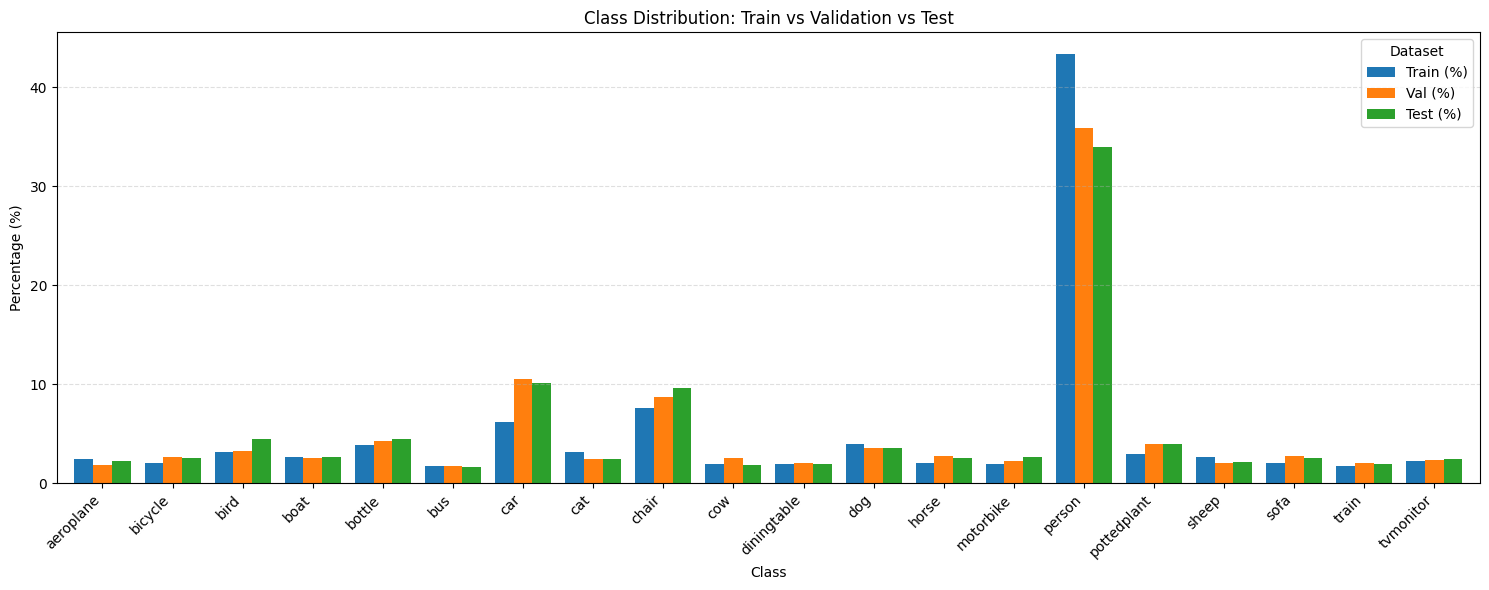

In [90]:
import pandas as pd
import matplotlib.pyplot as plt 

classes = sorted(set(train_counts) | set(test_counts) | set(val_counts))

df = pd.DataFrame({
    "Class": classes,
    "Train": [train_counts[c] for c in classes],
    "Test": [test_counts[c] for c in classes],
    "Val": [val_counts[c] for c in classes]
})

df["Train (%)"] = df["Train"] / df["Train"].sum() * 100
df["Test (%)"] = df["Test"] / df["Test"].sum() * 100
df["Val (%)"] = df["Val"] / df["Val"].sum() * 100

print(df.round(2).to_string(index=False))

df.plot(
    x="Class",
    y=["Train (%)", "Val (%)", "Test (%)"],
    kind="bar",
    figsize=(15, 6),
    width=0.8
)

plt.title("Class Distribution: Train vs Validation vs Test")
plt.xlabel("Class")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Dataset")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

### PascalVOCDataset

In [92]:

import os
import xml.etree.ElementTree as ET

import torch
from PIL import Image
from torch.utils.data import Dataset

VOC_CLASSES = [
    "__background__",
    "aeroplane", "bicycle", "bird", "boat", "bottle",
    "bus", "car", "cat", "chair", "cow",
    "diningtable", "dog", "horse", "motorbike", "person",
    "pottedplant", "sheep", "sofa", "train", "tvmonitor"
]

CLASS_TO_IDX = {
    name: idx for idx, name in enumerate(VOC_CLASSES)
}


class PascalVOCDataset(Dataset):

    def __init__(self, root, transforms=None, split=None):
        self.root = root
        self.transforms = transforms

        self.image_dir = os.path.join(root, "JPEGImages")
        self.annotation_dir = os.path.join(root, "Annotations")

        if split is not None:
            self.image_dir = os.path.join(self.image_dir, split)
            self.annotation_dir = os.path.join(self.annotation_dir, split)

        self.image_ids = sorted([
            f[:-4] for f in os.listdir(self.image_dir)
            if f.endswith(".jpg")
            and os.path.exists(
                os.path.join(self.annotation_dir, f[:-4] + ".xml")
            )
        ])

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, idx):

        image_id = self.image_ids[idx]

        image_path = os.path.join(
            self.image_dir, image_id + ".jpg"
        )

        annotation_path = os.path.join(
            self.annotation_dir, image_id + ".xml"
        )

        image = Image.open(image_path).convert("RGB")

        tree = ET.parse(annotation_path)
        root = tree.getroot()

        boxes = []
        labels = []
        iscrowd = []

        for obj in root.findall("object"):

            class_name = obj.find("name").text

            if class_name not in CLASS_TO_IDX:
                continue

            bbox = obj.find("bndbox")

            xmin = float(bbox.find("xmin").text) - 1
            ymin = float(bbox.find("ymin").text) - 1
            xmax = float(bbox.find("xmax").text) - 1
            ymax = float(bbox.find("ymax").text) - 1

            boxes.append([xmin, ymin, xmax, ymax])
            labels.append(CLASS_TO_IDX[class_name])

            difficult = obj.find("difficult")
            iscrowd.append(
                int(difficult.text) if difficult is not None else 0
            )

        boxes = torch.as_tensor(boxes, dtype=torch.float32)
        labels = torch.as_tensor(labels, dtype=torch.int64)

        width, height = image.size

        area = (
            (boxes[:, 2] - boxes[:, 0]) *
            (boxes[:, 3] - boxes[:, 1])
        )

        target = {
            "boxes": boxes,
            "labels": labels,
            "image_id": torch.tensor([idx]),
            "area": area,
            "iscrowd": torch.as_tensor(
                iscrowd, dtype=torch.int64
            )
        }

        if self.transforms is not None:
            image, target = self.transforms(image, target)

        return image, target


### Data transform

In [93]:
import random
import torchvision.transforms.functional as F

def transform_train(image, target):
    image = F.to_tensor(image)

    if random.random() < 0.5:
        image = F.hflip(image)

        width = image.shape[2]
        boxes = target["boxes"].clone()
        boxes[:, [0, 2]] = width - boxes[:, [2, 0]]
        target["boxes"] = boxes

    return image, target


def transform_test(image, target):
    image = F.to_tensor(image)
    return image, target

In [94]:
dataset_train = PascalVOCDataset(
    root=datapath_org_train,
    transforms=transform_train
)

dataset_val = PascalVOCDataset(
    root=datapath_org_test,
    transforms=transform_test,
    split="val"
)

dataset_test = PascalVOCDataset(
    root=datapath_org_test,
    transforms=transform_test,
    split="test"
)

In [95]:
print("Train:", len(dataset_train))
print("Val:", len(dataset_val))
print("Test:", len(dataset_test))

image, target = dataset_train[0]

print("Image shape:", image.shape)
print("Boxes shape:", target["boxes"].shape)
print("Labels shape:", target["labels"].shape)

Train: 17125
Val: 2459
Test: 2493
Image shape: torch.Size([3, 500, 486])
Boxes shape: torch.Size([1, 4])
Labels shape: torch.Size([1])


### Data loader

In [96]:
from torch.utils.data import DataLoader

def collate_fn(batch):
    return tuple(zip(*batch))

train_loader = DataLoader(
    dataset_train,
    batch_size=batch_size,
    shuffle=True,
    num_workers=num_workers,
    collate_fn=collate_fn,
    pin_memory=True
)

val_loader = DataLoader(
    dataset_val,
    batch_size=batch_size,
    shuffle=False,
    num_workers=num_workers,
    collate_fn=collate_fn,
    pin_memory=True
)

test_loader = DataLoader(
    dataset_test,
    batch_size=batch_size,
    shuffle=False,
    num_workers=num_workers,
    collate_fn=collate_fn,
    pin_memory=True
)

In [97]:
print("Dataset length:", len(dataset_train))

for i in range(4):
    print("Loading image:", i, flush=True)
    image, target = dataset_train[i]
    print("Loaded:", image.shape, flush=True)

Dataset length: 17125
Loading image: 0
Loaded: torch.Size([3, 500, 486])
Loading image: 1
Loaded: torch.Size([3, 281, 500])
Loading image: 2
Loaded: torch.Size([3, 366, 500])
Loading image: 3
Loaded: torch.Size([3, 375, 500])


### Visualize input image

In [98]:
import cv2

def draw_bbox_on_image(image, target):
    """
    image: NumPy image, format BGR
    target: Faster R-CNN target dictionary
    """

    boxes = target["boxes"]
    labels = target["labels"]

    for box, label in zip(boxes, labels):

        xmin, ymin, xmax, ymax = map(int, box.tolist())
        class_id = label.item()

        # Bounding box
        cv2.rectangle(
            image,
            (xmin, ymin),
            (xmax, ymax),
            (0, 255, 0),
            2
        )

        # Class name
        class_name = VOC_CLASSES[class_id]

        # Background for class name
        text_y = max(ymin - 30, 20)

        cv2.rectangle(
            image,
            (xmin, text_y - 20),
            (xmin + 120, text_y + 5),
            (0, 255, 0),
            -1
        )

        cv2.putText(
            image,
            class_name,
            (xmin + 2, text_y),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            (0, 0, 0),
            2
        )

    return image

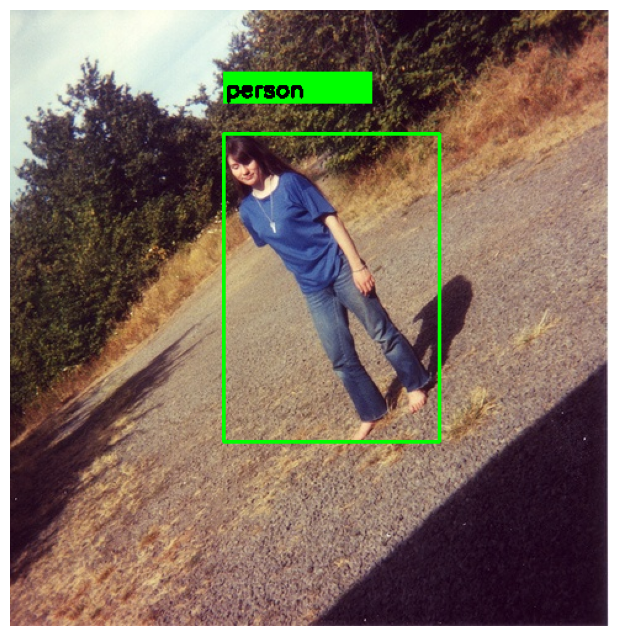

In [99]:
import matplotlib.pyplot as plt
import numpy as np

# Get sample
image, target = dataset_train[0]

# Tensor [C, H, W] -> NumPy [H, W, C]
image_np = image.permute(1, 2, 0).numpy()

# RGB -> BGR
image_cv = cv2.cvtColor(
    (image_np * 255).astype(np.uint8),
    cv2.COLOR_RGB2BGR
)

# Draw bounding boxes
image_drawn = draw_bbox_on_image(image_cv.copy(), target)

# BGR -> RGB for Matplotlib
image_drawn = cv2.cvtColor(image_drawn, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 8))
plt.imshow(image_drawn)
plt.axis("off")
plt.show()

In [100]:
print("Image ID:", target["image_id"].item())
print("Number of objects:", len(target["boxes"]))

for box, label, area in zip(
    target["boxes"],
    target["labels"],
    target["area"]
):
    print({
        "class": VOC_CLASSES[label.item()],
        "bbox": box.tolist(),
        "area": area.item()
    })

Image ID: 0
Number of objects: 1
{'class': 'person', 'bbox': [173.0, 100.0, 348.0, 350.0], 'area': 43750.0}


## Model preparation

### ROI

In [101]:
import torch
import torch.nn as nn
import torchvision

from torchvision.models import VGG16_Weights
from torchvision.models.detection import FasterRCNN
from torchvision.models.detection.rpn import AnchorGenerator
from torchvision.models.detection.faster_rcnn import TwoMLPHead

class RoIPoolWrapper(nn.Module):
    def __init__(self, output_size=7, spatial_scale=1/16):
        super().__init__()

        self.pool = torchvision.ops.RoIPool(
            output_size=output_size,
            spatial_scale=spatial_scale
        )

    def forward(self, features, proposals, image_shapes):
        return self.pool(features["0"], proposals)

### Faster RCNN with VGG16 backbone

In [102]:
from torchvision.models.detection.faster_rcnn import (
    TwoMLPHead,
    FastRCNNPredictor
)
from torchvision.ops import MultiScaleRoIAlign

def load_faster_rcnn_v1_base_vgg(num_classes=21):
    vgg = torchvision.models.vgg16(
        weights=VGG16_Weights.IMAGENET1K_V1
    )

    backbone = nn.Sequential(
        *list(vgg.features.children())[:-1]
    )
    backbone.out_channels = 512

    for param in backbone.parameters():
        param.requires_grad = False

    anchor_generator = AnchorGenerator(
        sizes=((128, 256, 512),),
        aspect_ratios=((0.5, 1.0, 2.0),)
    )

    roi_pooler = MultiScaleRoIAlign(
    featmap_names=["0"],
    output_size=(7, 7),
    sampling_ratio=2
)

    # Two fully connected layers: 25088 -> 4096 -> 4096
    box_head = TwoMLPHead(
        in_channels=512 * 7 * 7,
        representation_size=4096
    )

    # Initialize FC6 and FC7 from pretrained VGG16
    with torch.no_grad():
        box_head.fc6.weight.copy_(vgg.classifier[0].weight)
        box_head.fc6.bias.copy_(vgg.classifier[0].bias)
        box_head.fc7.weight.copy_(vgg.classifier[3].weight)
        box_head.fc7.bias.copy_(vgg.classifier[3].bias)

    # IMPORTANT: Predictor must receive 4096 features
    box_predictor = FastRCNNPredictor(
        in_channels=4096,
        num_classes=num_classes
    )

    model = FasterRCNN(
        backbone=backbone,
        num_classes=None,
        rpn_anchor_generator=anchor_generator,
        box_roi_pool=roi_pooler,
        box_head=box_head,
        box_predictor=box_predictor,
        min_size=600,
        max_size=1000
    )

    return model

model_fasterrcnn_v1 = load_faster_rcnn_v1_base_vgg().to(device)

In [103]:
from torchinfo import summary

def helper_display_model_info(model, model_name="Faster R-CNN"):

    print(f"\n{'=' * 70}")
    print(f"MODEL SUMMARY: {model_name}")
    print(f"{'=' * 70}")

    # Architecture
    print(model)

    # Parameter summary
    summary(
        model,
        depth=3,
        col_names=["num_params", "trainable"],
        verbose=1
    )

    # Count parameters
    total_params = sum(
        p.numel() for p in model.parameters()
    )

    trainable_params = sum(
        p.numel() for p in model.parameters()
        if p.requires_grad
    )

    frozen_params = total_params - trainable_params

    print(f"\n{'-' * 70}")
    print(f"Total Parameters:     {total_params:,}")
    print(f"Trainable Parameters: {trainable_params:,}")
    print(f"Frozen Parameters:    {frozen_params:,}")
    print(f"{'-' * 70}")

helper_display_model_info(model_fasterrcnn_v1)


MODEL SUMMARY: Faster R-CNN
FasterRCNN(
  (transform): GeneralizedRCNNTransform(
      Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
      Resize(min_size=(600,), max_size=1000, mode='bilinear')
  )
  (backbone): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padd

In [104]:
def helper_check_trainable_params(model):

    components = {
        "Backbone": model.backbone,
        "RPN": model.rpn,
        "ROI Pooler": model.roi_heads.box_roi_pool,
        "ROI Box Head": model.roi_heads.box_head,
        "ROI Predictor": model.roi_heads.box_predictor
    }

    for name, module in components.items():
        params = list(module.parameters())

        total = sum(p.numel() for p in params)
        trainable = sum(
            p.numel() for p in params if p.requires_grad
        )

        print(
            f"{name:<18} "
            f"Total: {total:>12,} | "
            f"Trainable: {trainable:>12,} | "
            f"Frozen: {total - trainable:>12,}"
        )

helper_check_trainable_params(model_fasterrcnn_v1)

Backbone           Total:   14,714,688 | Trainable:            0 | Frozen:   14,714,688
RPN                Total:    2,382,893 | Trainable:    2,382,893 | Frozen:            0
ROI Pooler         Total:            0 | Trainable:            0 | Frozen:            0
ROI Box Head       Total:  119,545,856 | Trainable:  119,545,856 | Frozen:            0
ROI Predictor      Total:      430,185 | Trainable:      430,185 | Frozen:            0


### Optimizer & Scheduler

In [106]:
class modelOpt_SGD():
    def __init__(
        self,
        model,
        lr_bb=0.0001,
        lr_head=0.001,
        mm=0.9,
        weight_decay=0.001
    ):
        self.model = model
        self.lr_bb = lr_bb
        self.lr_head = lr_head
        self.mm = mm
        self.weight_decay = weight_decay

        # 1. Backbone parameters (VGG16)
        backbone_params = list(self.model.backbone.parameters())

        # 2. Detection head parameters (RPN + RoI Heads)
        head_params = (
            list(self.model.rpn.parameters()) +
            list(self.model.roi_heads.parameters())
        )

        # 3. SGD optimizer with separate learning rates
        self.optimizer = torch.optim.SGD(
            [
                {
                    'params': backbone_params,
                    'lr': self.lr_bb
                },
                {
                    'params': head_params,
                    'lr': self.lr_head
                }
            ],
            momentum=self.mm,
            weight_decay=self.weight_decay
        )

    def zero_grad(self):
        self.optimizer.zero_grad(set_to_none=True)

    def step(self):
        self.optimizer.step()

    def get_lr(self):
        return {
            'lr_bb': self.optimizer.param_groups[0]['lr'],
            'lr_head': self.optimizer.param_groups[1]['lr']
        }


In [105]:
class modelScheduler_StepLR():
    def __init__(self, optimizer, step_size=10, gamma=0.1):
        self.optimizer = optimizer
        self.step_size = step_size
        self.gamma = gamma
        self.scheduler = torch.optim.lr_scheduler.StepLR(self.optimizer, step_size=self.step_size, gamma=self.gamma)

    def scheduler_step(self):
        self.scheduler.step()

In [107]:
model_fasterrcnn_v1_opt = modelOpt_SGD(
    model=model_fasterrcnn_v1,
    lr_bb=lr_bb,
    lr_head=lr_head,
    mm=momentum,
    weight_decay=weight_decay
)

model_fasterrcnn_v1_scheduler = modelScheduler_StepLR(
    optimizer=model_fasterrcnn_v1_opt.optimizer,
    step_size=lr_step_size,
    gamma=lr_gamma
)

### Store history and result

In [108]:
history_fasterrcnn_v1 = {
    "epoch": [],
    "train_loss": [],
    "val_loss": [],

    # Training time
    "epoch_time": [],

    # Learning rate
    "lr_bb": [],
    "lr_head": [],

    # Individual training losses
    "train_loss_objectness": [],
    "train_loss_rpn_box_reg": [],
    "train_loss_classifier": [],
    "train_loss_box_reg": [],

    # Validation metrics
    "val_map": [],
    "val_map_50": [],
    "val_map_75": []
}

result_fasterrcnn_v1 = {
    # Test metrics
    "test_loss": 0.0,
    "test_map": 0.0,
    "test_map_50": 0.0,
    "test_map_75": 0.0,

    # Detection metrics
    "precision": 0.0,
    "recall": 0.0,
    "f1_score": 0.0,

    # Performance
    "train_time": 0.0,
    "test_time": 0.0,
    "inference_time_per_image": 0.0,

    # Model complexity
    "total_params": 0,
    "trainable_params": 0,

    # Best training results
    "min_train_loss": 0.0,
    "min_val_loss": 0.0,
    "max_val_map": 0.0,
    "max_val_map_50": 0.0,
    "max_val_map_75": 0.0,

    # Best epoch
    "best_epoch": 0
}

### Training

In [109]:

import torch
import time
import os

def train_one_epoch(
    model,
    train_loader,
    optimizer,
    device,
    epoch,
    print_freq=50
):
    model.train()

    total_loss = 0.0
    start_time = time.time()
    for batch_idx, (images, targets) in enumerate(train_loader):
        # Move images and targets to device
        images = [img.to(device) for img in images]

        targets = [
            {k: v.to(device) for k, v in target.items()}
            for target in targets
        ]
        
        # Forward pass
        loss_dict = model(images, targets)

        # Calculate total loss
        losses = sum(loss for loss in loss_dict.values())

        # Backpropagation
        optimizer.zero_grad()
        losses.backward()
        optimizer.step()

        total_loss += losses.item()

        # Print training information
        if (batch_idx + 1) % print_freq == 0:
            print(
                f"Epoch [{epoch}] "
                f"Iteration [{batch_idx + 1}/{len(train_loader)}] "
                f"Loss: {losses.item():.4f} "
                f"RPN Objectness: {loss_dict['loss_objectness'].item():.4f} "
                f"RPN Box: {loss_dict['loss_rpn_box_reg'].item():.4f} "
                f"ROI Class: {loss_dict['loss_classifier'].item():.4f} "
                f"ROI Box: {loss_dict['loss_box_reg'].item():.4f}"
            )

    avg_loss = total_loss / len(train_loader)
    epoch_time = time.time() - start_time

    return avg_loss, epoch_time


In [111]:
import torch

print("CUDA available:", torch.cuda.is_available())
print("CUDA version:", torch.version.cuda)
print("GPU count:", torch.cuda.device_count())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("Model device:", next(model_fasterrcnn_v1.parameters()).device)

CUDA available: True
CUDA version: 12.1
GPU count: 1
GPU: NVIDIA RTX 3500 Ada Generation Laptop GPU
Model device: cuda:0


In [ ]:
import time

num_epochs = epochs
best_val_map = 0.0
total_training_time = 0

os.makedirs("checkpoints", exist_ok=True)

for epoch in range(1, num_epochs + 1):

    print(f"\n========== Epoch {epoch}/{num_epochs} ==========")

    # 1. Train
    train_loss, epoch_time = train_one_epoch(
        model=model_fasterrcnn_v1,
        train_loader=train_loader,
        optimizer=model_fasterrcnn_v1_opt,
        device=device,
        epoch=epoch,
        print_freq=print_freq
    )


    # 2. Evaluate validation mAP
    val_metrics = evaluate_model(
        model=model_fasterrcnn_v1,
        data_loader=val_loader,
        device=device
    )

    val_map = val_metrics["map"]
    val_map_50 = val_metrics["map_50"]
    val_map_75 = val_metrics["map_75"]

    val_map = val_metrics["map"]

    # 3. Record history
    current_lr = model_fasterrcnn_v1_opt.get_lr()

    history_fasterrcnn_v1["train_loss"].append(train_loss)
    history_fasterrcnn_v1["val_map"].append(val_map)
    history_fasterrcnn_v1["lr_bb"].append(current_lr["lr_bb"])
    history_fasterrcnn_v1["lr_head"].append(current_lr["lr_head"])
    history_fasterrcnn_v1["epoch_time"].append(epoch_time)
    history_fasterrcnn_v1["epoch"].append(epoch)
    history_fasterrcnn_v1["val_map"].append(val_map)
    history_fasterrcnn_v1["val_map_50"].append(val_map_50)
    history_fasterrcnn_v1["val_map_75"].append(val_map_75)

    print(f"Train Loss: {train_loss:.4f} | Val mAP: {val_map:.4f} | mAP@50: {val_map_50:.4f} | mAP@75: {val_map_75:.4f} | Time: {epoch_time:.2f}s")

    # 4. Update scheduler
    model_fasterrcnn_v1_scheduler.scheduler_step()

    # 5. Save LAST
    checkpoint = {
        "epoch": epoch,
        "model_state_dict": model_fasterrcnn_v1.state_dict(),
        "optimizer_state_dict": model_fasterrcnn_v1_opt.optimizer.state_dict(),
        "scheduler_state_dict": model_fasterrcnn_v1_scheduler.scheduler.state_dict(),
        "train_loss": train_loss,
        "val_map": val_map,
        "history": history_fasterrcnn_v1
    }

    torch.save(
        checkpoint,
        "checkpoints/fasterrcnn_v1_last.pth"
    )

    # 6. Save BEST
    if val_map > best_val_map:
        best_val_map = val_map

        torch.save(
            checkpoint,
            "checkpoints/fasterrcnn_v1_best.pth"
        )

        print(f"Best checkpoint updated: {best_val_map:.4f}")


    total_training_time += epoch_time

print("\nTraining completed!")


========== Epoch 1/20 ==========
Epoch [1] Iteration [50/4282] Loss: 2.1073 RPN Objectness: 0.6159 RPN Box: 0.0545 ROI Class: 0.9023 ROI Box: 0.5346
Epoch [1] Iteration [100/4282] Loss: 1.3299 RPN Objectness: 0.5508 RPN Box: 0.0648 ROI Class: 0.4867 ROI Box: 0.2276
Epoch [1] Iteration [150/4282] Loss: 1.4544 RPN Objectness: 0.4626 RPN Box: 0.0571 ROI Class: 0.5149 ROI Box: 0.4198
Epoch [1] Iteration [200/4282] Loss: 1.9680 RPN Objectness: 0.6090 RPN Box: 0.2651 ROI Class: 0.6899 ROI Box: 0.4040
Epoch [1] Iteration [250/4282] Loss: 1.7119 RPN Objectness: 0.5093 RPN Box: 0.1969 ROI Class: 0.5428 ROI Box: 0.4629
Epoch [1] Iteration [300/4282] Loss: 1.5557 RPN Objectness: 0.5104 RPN Box: 0.1679 ROI Class: 0.5395 ROI Box: 0.3380
Epoch [1] Iteration [350/4282] Loss: 1.1462 RPN Objectness: 0.3389 RPN Box: 0.0889 ROI Class: 0.4046 ROI Box: 0.3139
Epoch [1] Iteration [400/4282] Loss: 1.4509 RPN Objectness: 0.5202 RPN Box: 0.4606 ROI Class: 0.2620 ROI Box: 0.2081
Epoch [1] Iteration [450/4282] 

### Evaluation

In [ ]:

import torch
from torchvision.ops import box_iou
from torchmetrics.detection import MeanAveragePrecision


def evaluate_model(model, data_loader, device, score_threshold=0.5):

    model.eval()

    metric = MeanAveragePrecision(
        box_format="xyxy",
        iou_type="bbox"
    ).to(device)

    TP, FP, FN = 0, 0, 0

    with torch.no_grad():

        for images, targets in data_loader:

            images = [img.to(device) for img in images]
            predictions = model(images)

            predictions_metric = []

            for pred, target in zip(predictions, targets):

                gt_boxes = target["boxes"].to(device)
                gt_labels = target["labels"].to(device)

                pred_boxes = pred["boxes"]
                pred_labels = pred["labels"]
                pred_scores = pred["scores"]

                # Keep predictions above confidence threshold
                keep = pred_scores >= score_threshold

                filtered_boxes = pred_boxes[keep]
                filtered_labels = pred_labels[keep]
                filtered_scores = pred_scores[keep]

                # Store all predictions for mAP
                predictions_metric.append({
                    "boxes": pred_boxes,
                    "scores": pred_scores,
                    "labels": pred_labels
                })

                matched_gt = set()

                if len(filtered_boxes) > 0 and len(gt_boxes) > 0:

                    ious = box_iou(filtered_boxes, gt_boxes)

                    # Match predictions by descending confidence
                    order = torch.argsort(
                        filtered_scores,
                        descending=True
                    )

                    for pred_idx in order:

                        same_class = (
                            filtered_labels[pred_idx] == gt_labels
                        )

                        valid_ious = ious[pred_idx].clone()
                        valid_ious[~same_class] = 0

                        for gt_idx in matched_gt:
                            valid_ious[gt_idx] = 0

                        best_iou, best_gt = valid_ious.max(dim=0)

                        if best_iou >= 0.5:
                            TP += 1
                            matched_gt.add(best_gt.item())
                        else:
                            FP += 1

                else:
                    FP += len(filtered_boxes)

                FN += len(gt_boxes) - len(matched_gt)

            metric.update(
                predictions_metric,
                [
                    {
                        "boxes": t["boxes"].to(device),
                        "labels": t["labels"].to(device)
                    }
                    for t in targets
                ]
            )

    results = metric.compute()

    precision = TP / (TP + FP) if TP + FP > 0 else 0.0
    recall = TP / (TP + FN) if TP + FN > 0 else 0.0

    output = {
        "map_50": results["map_50"].item(),
        "map_75": results["map_75"].item(),
        "map": results["map"].item(),
        "precision": precision,
        "recall": recall
    }

    print(
        f"mAP@0.5: {output['map_50']:.4f} | "
        f"mAP@0.75: {output['map_75']:.4f} | "
        f"mAP@0.5:0.95: {output['map']:.4f} | "
        f"Precision@0.5: {precision:.4f} | "
        f"Recall@0.5: {recall:.4f}"
    )

    return output